# Arabic Sentiment Dataset — Complete Data Understanding

**Purpose:** inspect the raw `alldata.csv` and the supplied `train/dev/test` splits, prove the data-quality findings with reproducible code, and record the observations that will later justify the final data-preparation decisions.

> Keep the raw files unchanged. Run each code cell, inspect the output, then write your own observation in the Markdown cell immediately below it.

## 0. Setup

This notebook is **data understanding only**. Do not train AraBERT here yet.

In [1]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 42

# Run this notebook from notebooks/ so ../data/raw points to the project raw-data folder.
RAW_DIR = Path("../data/raw")
ALLDATA_PATH = RAW_DIR / "alldata.csv"
TRAIN_PATH = RAW_DIR / "train.csv"
DEV_PATH = RAW_DIR / "dev.csv"
TEST_PATH = RAW_DIR / "test.csv"

print("Raw-data directory:", RAW_DIR.resolve())
print("alldata exists:", ALLDATA_PATH.exists())
print("train exists:", TRAIN_PATH.exists())
print("dev exists:", DEV_PATH.exists())
print("test exists:", TEST_PATH.exists())

Raw-data directory: E:\03 Education\Online Courses\MLOps MENA\Final Project\arabic-sentiment-mlops\data\raw
alldata exists: True
train exists: True
dev exists: True
test exists: True


### My observation
Write what you observed about the files that are present and whether the expected raw artifacts exist.

## 1. Load `alldata.csv` and prove its structure

We explicitly use `header=None` because the raw artifact is headerless.

In [2]:
alldata = pd.read_csv(ALLDATA_PATH)

print("Shape:", alldata.shape)
print("Columns:", alldata.columns.tolist())
print("\nFirst 5 rows:")
display(alldata.head())
print("\nLast 5 rows:")
display(alldata.tail())
print("\nData types:")
print(alldata.dtypes)

Shape: (110759, 2)
Columns: ['جميل لكن نريد خاصية لقفل التطبيق بعد مد معين يحددا الاب لأن الطفل لن يتوقف', 'NEUTRAL']

First 5 rows:


,جميل لكن نريد خاصية لقفل التطبيق بعد مد معين يحددا الاب لأن الطفل لن يتوقف,NEUTRAL
0,ابني اتعلم نطق الحروف بسرعة كبيرة ان حق برنامج...,NEUTRAL
1,تطبيق رائع جدا وطريقة عرض الحروف ممتعة ومبسطة ...,POSITIVE
2,جميلة وممتع ومفيدة للاطفال الصغار,NEUTRAL
3,ممتاز وآمن للأطفال أفضل من كثير من التطبيقات ...,POSITIVE
4,يساعد الاطفال على تعلم الاحرف ونطقا وكتابتا,NEGATIVE



Last 5 rows:


,جميل لكن نريد خاصية لقفل التطبيق بعد مد معين يحددا الاب لأن الطفل لن يتوقف,NEUTRAL
110754,حجم مناسب,NEUTRAL
110755,جميل اتعب اقول جميل شكر نون,NEUTRAL
110756,سيء جدا جدا وضعيف وفكرت ارميا من اول يوم,NEGATIVE
110757,حلوة وحجما كبير وقوية بس كثير تتحمل ملابس بس م...,NEUTRAL
110758,المعدن خفيف لكن يتحمل اللون بن,NEUTRAL



Data types:
جميل لكن نريد خاصية لقفل التطبيق بعد مد معين يحددا الاب لأن الطفل لن يتوقف    str
NEUTRAL                                                                       str
dtype: object


In [3]:
alldata = pd.read_csv(
    ALLDATA_PATH,
    header=None,
    names=["text", "label"],
    encoding="utf-8-sig",
    dtype={"text": "string", "label": "string"},
)

print("Shape:", alldata.shape)
print("Columns:", alldata.columns.tolist())
print("\nFirst 5 rows:")
display(alldata.head())
print("\nLast 5 rows:")
display(alldata.tail())
print("\nData types:")
print(alldata.dtypes)

Shape: (110760, 2)
Columns: ['text', 'label']

First 5 rows:


,text,label
0,جميل لكن نريد خاصية لقفل التطبيق بعد مد معين ي...,NEUTRAL
1,ابني اتعلم نطق الحروف بسرعة كبيرة ان حق برنامج...,NEUTRAL
2,تطبيق رائع جدا وطريقة عرض الحروف ممتعة ومبسطة ...,POSITIVE
3,جميلة وممتع ومفيدة للاطفال الصغار,NEUTRAL
4,ممتاز وآمن للأطفال أفضل من كثير من التطبيقات ...,POSITIVE



Last 5 rows:


,text,label
110755,حجم مناسب,NEUTRAL
110756,جميل اتعب اقول جميل شكر نون,NEUTRAL
110757,سيء جدا جدا وضعيف وفكرت ارميا من اول يوم,NEGATIVE
110758,حلوة وحجما كبير وقوية بس كثير تتحمل ملابس بس م...,NEUTRAL
110759,المعدن خفيف لكن يتحمل اللون بن,NEUTRAL



Data types:
text     string
label    string
dtype: object


### My observation
Record: number of rows, number of columns, whether the file has a header, and what the first/last records look like.

## 2. Missing values and malformed records

Before doing NLP, verify that text and labels are present. A missing label is especially important because it cannot be used for supervised training without external ground truth.

In [4]:
missing_text = int(alldata["text"].isna().sum())
missing_label = int(alldata["label"].isna().sum())
empty_text = int(alldata["text"].fillna("").str.strip().eq("").sum())

print("Missing text:", missing_text)
print("Missing label:", missing_label)
print("Empty/blank text:", empty_text)

if missing_text or missing_label:
    print("\nRows with missing fields:")
    display(alldata[alldata["text"].isna() | alldata["label"].isna()])

Missing text: 0
Missing label: 1
Empty/blank text: 0

Rows with missing fields:


,text,label
3294,العبة حلوة أوي أحسن لعبة وجميلة و حلوة أوNEUTRAL,<NA>


### My observation
Write whether missing text/labels exist, how many rows are affected, and what the malformed row looks like if one exists.

## 3. Label vocabulary and class distribution

          count  percent
label                   
NEGATIVE  46827    42.28
NEUTRAL   32129    29.01
POSITIVE  31803    28.71
<NA>          1      0.0

Unique non-null labels: ['NEUTRAL', 'POSITIVE', 'NEGATIVE']


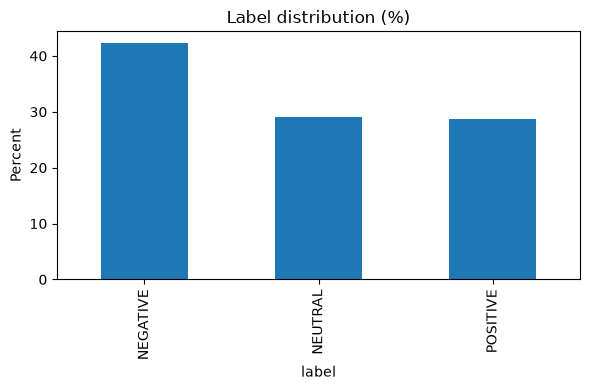

In [5]:
label_counts = alldata["label"].value_counts(dropna=False)
label_pct = (alldata["label"].value_counts(normalize=True, dropna=False) * 100).round(2)
label_summary = pd.DataFrame({"count": label_counts, "percent": label_pct})
print(label_summary)

# Also show only labeled rows.
valid = alldata.dropna(subset=["label"]).copy()
print("\nUnique non-null labels:", valid["label"].drop_duplicates().tolist())

ax = label_pct.drop(index=[x for x in label_pct.index if pd.isna(x)], errors="ignore").plot(
    kind="bar", figsize=(6, 4), title="Label distribution (%)"
)
ax.set_ylabel("Percent")
plt.tight_layout()
plt.show()

### My observation
Record the three sentiment labels, their frequencies, and whether the dataset is balanced or imbalanced.

## 4. Verify the semantic meaning of each label from real examples

The `alldata.csv` artifact already uses explicit label names, so this check is about verifying that the text examples are qualitatively consistent with those names.

In [6]:
for label in ["NEGATIVE", "NEUTRAL", "POSITIVE"]:
    print(f"\n===== {label} =====")
    sample = valid.loc[valid["label"].eq(label), ["text", "label"]].sample(5, random_state=RANDOM_STATE)
    display(sample.reset_index(drop=True))


===== NEGATIVE =====


,text,label
0,عالم الاحياء اكثر تعفونا الف مرة من عالم الامو...,NEGATIVE
1,اعجبني مر وبطلب كمان,NEGATIVE
2,الل يعطيك الف عافية للأمانة كلمة شكر لا تكفي ف...,NEGATIVE
3,مقبول الغرف ضيق وازعاج في الممرات,NEGATIVE
4,مخيب للأمل موقعة من شارع الرقة عدم الراحة بسبب...,NEGATIVE



===== NEUTRAL =====


,text,label
0,جيد موقع الفندق ونظافة وتوفر مواقف سيارات وتعا...,NEUTRAL
1,تجرب جميل وفندق انصح ب موقع متميز طقم عمل ودو...,NEUTRAL
2,بالرغم من اني حسيت بالملل في نصا يمكن عشان ثق...,NEUTRAL
3,جميل و لكن ناك فقط ٤ مراحل مفتوح و الباقي مغلق...,NEUTRAL
4,جيد خدمة موظفين الاستقبال غير لا أقين في التع...,NEUTRAL



===== POSITIVE =====


,text,label
0,ممتاز وثقيل,POSITIVE
1,رحلة التزلج والل الصراح خدمتم ولا اروع ولا شي,POSITIVE
2,ألعاب ولاأروع إنا ممتعة جدامن بينات كل الألعاب...,POSITIVE
3,تعامل مميز,POSITIVE
4,ما أجمل البياض قبل أن يتوسخ بحبر الكتابة,POSITIVE


### My observation
For each class, describe whether the sample texts are consistent with the sentiment label. Mention any ambiguous or noisy examples you notice.

## 5. Exact duplicates

First measure duplicates using the original text exactly as stored.

In [7]:
exact_duplicate_rows = int(valid["text"].duplicated().sum())
unique_exact_texts = int(valid["text"].nunique(dropna=True))

print("Valid labeled rows:", len(valid))
print("Unique exact texts:", unique_exact_texts)
print("Duplicate rows beyond first occurrence:", exact_duplicate_rows)
print("Rows that are unique:", len(valid) - exact_duplicate_rows)

print("\nMost frequent exact duplicates:")
display(valid["text"].value_counts().head(15).rename("count").to_frame())

Valid labeled rows: 110759
Unique exact texts: 88871
Duplicate rows beyond first occurrence: 21888
Rows that are unique: 88871

Most frequent exact duplicates:


,count
text,
ممتاز,6
ان جميل,6
حلو مر,6
جيد,5
جميل,5
حلو,5
جميلة جدا,5
أعجبني كثيرا,5
رائعة,5


### My observation
Record whether duplicates are rare or substantial. Mention the most repeated examples and why duplicate text can make evaluation misleading.

## 6. Canonical text: stronger duplicate/leakage key

We use the same idea as the preparation logic: normalize whitespace and remove Arabic diacritics/tatweel **only for duplicate detection**, not as the training text itself.

In [8]:
WS_RE = re.compile(r"\s+")
DIACRITICS_RE = re.compile(r"[\u064B-\u0652\u0670\u0640]")

def canonical(text: str) -> str:
    return WS_RE.sub(" ", DIACRITICS_RE.sub("", text)).strip()

valid["canonical_text"] = valid["text"].map(canonical)

canonical_unique = int(valid["canonical_text"].nunique())
canonical_duplicate_rows = int(valid["canonical_text"].duplicated().sum())

print("Unique canonical texts:", canonical_unique)
print("Duplicate rows by canonical key:", canonical_duplicate_rows)
print("Top canonical duplicates:")
display(valid["canonical_text"].value_counts().head(20).rename("count").to_frame())

Unique canonical texts: 88757
Duplicate rows by canonical key: 22002
Top canonical duplicates:


,count
canonical_text,
شكرا جزيلا,14
جميل جدا,12
شكرا,12
رائع جدا,12
ممتاز جدا,10
شكرا لك,10
لعب جميل جدا,8
جميل جدا جدا,8
حلو مر,8


### My observation
Explain why canonical duplicates can reveal hidden duplicates that exact-string matching misses, especially when Arabic diacritics or whitespace differ.

## 7. Conflicting labels for the same canonical text

This is one of the most important quality checks: the exact same normalized review should not appear with different sentiment labels in a clean supervised dataset.

In [9]:
label_nunique_per_key = valid.groupby("canonical_text")["label"].nunique()
conflicting_keys = label_nunique_per_key[label_nunique_per_key > 1].index
conflicting_rows = valid[valid["canonical_text"].isin(conflicting_keys)].copy()

print("Conflicting canonical texts:", len(conflicting_keys))
print("Rows belonging to conflicting texts:", len(conflicting_rows))

for key in list(conflicting_keys)[:20]:
    group = valid.loc[valid["canonical_text"].eq(key), ["text", "label"]]
    print("\nCanonical key:", repr(key))
    display(group.reset_index(drop=True))

Conflicting canonical texts: 19
Rows belonging to conflicting texts: 108

Canonical key: 'جميلة جدا'


,text,label
0,جميلة جدا,POSITIVE
1,جميلة جدا,POSITIVE
2,جميلة جدا,POSITIVE
3,جميلة جدا,POSITIVE
4,جميلة جداً,NEUTRAL
5,جميلة جدا,POSITIVE
6,جميلة جداً,NEUTRAL



Canonical key: 'جميييل جدا'


,text,label
0,جميييل جدا,NEGATIVE
1,جميييل جداً,POSITIVE
2,جميييل جدا,NEGATIVE
3,جميييل جداً,POSITIVE
4,جميييل جدا,NEGATIVE



Canonical key: 'حلو جدا'


...

,text,label
0,لعبة جميل جداً,NEUTRAL
1,لعبة جميل جدا,POSITIVE
2,لعبة جميل جداً,NEUTRAL
3,لعبة جميل جدا,POSITIVE



Canonical key: 'متعاون جدا'


,text,label
0,متعاون جدا,POSITIVE
1,متعاون جداً,NEUTRAL
2,متعاون جدا,POSITIVE
3,متعاون جداً,NEUTRAL



Canonical key: 'متعاون جدا ومحترم'


,text,label
0,متعاون جدًا ومحترم,NEUTRAL
1,متعاون جدا ومحترم,POSITIVE
2,متعاون جدًا ومحترم,NEUTRAL
3,متعاون جدا ومحترم,POSITIVE


### My observation
Record how many conflicting text groups exist and what pattern you see. Pay attention to very short ambiguous phrases and differences that disappear after normalization.

## 8. How much data would remain after conservative cleaning?

Cleaning policy for this analysis:
1. remove rows with missing labels
2. remove every row belonging to a conflicting canonical-text group
3. keep one occurrence of each remaining canonical text

Do **not** overwrite the raw file.

In [10]:
clean_candidate = valid.loc[~valid["canonical_text"].isin(conflicting_keys)].copy()
clean_candidate = clean_candidate.drop_duplicates(subset=["canonical_text"], keep="first").reset_index(drop=True)

print("Raw rows:", len(alldata))
print("After dropping missing labels:", len(valid))
print("After removing conflicting groups:", len(valid.loc[~valid["canonical_text"].isin(conflicting_keys)]))
print("After canonical deduplication:", len(clean_candidate))
print("Rows retained from valid labeled data: {:.2f}%".format(100 * len(clean_candidate) / len(valid)))

clean_label_summary = pd.DataFrame({
    "count": clean_candidate["label"].value_counts(),
    "percent": (clean_candidate["label"].value_counts(normalize=True) * 100).round(2),
})
print("\nClean candidate class distribution:")
print(clean_label_summary)

Raw rows: 110760
After dropping missing labels: 110759
After removing conflicting groups: 110651
After canonical deduplication: 88738
Rows retained from valid labeled data: 80.12%

Clean candidate class distribution:
          count  percent
label                   
NEGATIVE  41385    46.64
NEUTRAL   25269    28.48
POSITIVE  22084    24.89


### My observation
Record how many rows remain after cleaning and whether the class imbalance changed. Explain why deduplication changes the effective sample size.

## 9. Text length analysis

Measure both character and word lengths. This will later help us choose an AraBERT `max_length` based on evidence rather than assumption.

Character-length summary:
count    88738.0
mean      154.16
std       347.32
min          1.0
50%         70.0
90%        309.0
95%        556.0
99%       1543.0
max       7858.0
Name: char_length, dtype: Float64

Word-length summary:
count    88738.00
mean        28.95
std         65.68
min          1.00
50%         13.00
90%         58.00
95%        105.00
99%        295.00
max       1485.00
Name: word_length, dtype: float64


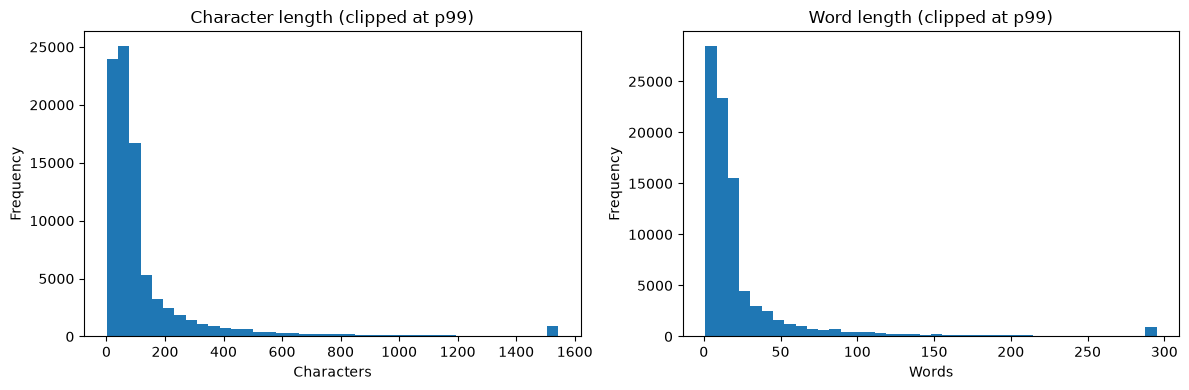

In [11]:
clean_candidate["char_length"] = clean_candidate["text"].str.len()
clean_candidate["word_length"] = clean_candidate["text"].str.split().str.len()

print("Character-length summary:")
print(clean_candidate["char_length"].describe(percentiles=[0.50, 0.90, 0.95, 0.99]).round(2))
print("\nWord-length summary:")
print(clean_candidate["word_length"].describe(percentiles=[0.50, 0.90, 0.95, 0.99]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
clean_candidate["char_length"].clip(upper=clean_candidate["char_length"].quantile(0.99)).plot(kind="hist", bins=40, ax=axes[0], title="Character length (clipped at p99)")
clean_candidate["word_length"].clip(upper=clean_candidate["word_length"].quantile(0.99)).plot(kind="hist", bins=40, ax=axes[1], title="Word length (clipped at p99)")
axes[0].set_xlabel("Characters")
axes[1].set_xlabel("Words")
plt.tight_layout()
plt.show()

### My observation
Record the median, long-tail behavior, and whether a small or large tokenizer max length seems reasonable. Do not choose `max_length` yet from this cell alone.

## 10. Estimate truncation pressure for candidate AraBERT sequence lengths

This is still a data analysis, not a final model decision.

In [12]:
# Word counts are only a proxy for subword-token counts, so treat these as a screening signal.
for n in [64, 128, 256, 384, 512]:
    pct_longer = 100 * (clean_candidate["word_length"] > n).mean()
    print(f"> {n:3d} words: {pct_longer:6.2f}% of reviews")

print("\nImportant: AraBERT uses subword tokenization, so final truncation rates must be measured with the actual tokenizer.")

>  64 words:   8.90% of reviews
> 128 words:   3.88% of reviews
> 256 words:   1.29% of reviews
> 384 words:   0.60% of reviews
> 512 words:   0.34% of reviews

Important: AraBERT uses subword tokenization, so final truncation rates must be measured with the actual tokenizer.


### My observation
Record which candidate lengths appear likely to truncate a meaningful fraction of the corpus and note that the final answer must come from the actual AraBERT tokenizer.

## 11. Rating-headline / shortcut analysis

Some records start with words such as `ممتاز`, `رائع`, `جيد`, `مقبول`, `ضعيف`, etc. We inspect this pattern before deciding whether to remove anything.

In [13]:
HEADLINES = [
    "مخيب للأمل", "مخيب", "ضعيف", "مقبول", "مرضي",
    "جيد", "رائع", "ممتاز", "استثنائي",
]
HEADLINE_RE = re.compile(r"^(?:" + "|".join(map(re.escape, HEADLINES)) + r")\s+")

headline_mask = valid["text"].str.contains(HEADLINE_RE, regex=True, na=False)
headline_rows = valid.loc[headline_mask].copy()

print("Rows starting with a rating-like headline:", len(headline_rows))
print("Percent of valid rows: {:.2f}%".format(100 * len(headline_rows) / len(valid)))
print("\nHeadline counts:")
print(
    headline_rows["text"]
    .str.extract(r"^(" + "|".join(map(re.escape, HEADLINES)) + r")")[0]
    .value_counts()
)
print("\nHeadline rows by label:")
print(pd.crosstab(index=pd.Series(True, index=headline_rows.index), columns=headline_rows["label"]))
print("\nExamples:")
display(headline_rows[["text", "label"]].sample(min(15, len(headline_rows)), random_state=RANDOM_STATE).reset_index(drop=True))

Rows starting with a rating-like headline: 18458
Percent of valid rows: 16.67%

Headline counts:
0
جيد           3791
ممتاز         2859
مرضي          2399
ضعيف          2028
مقبول         2010
استثنائي      1951
رائع          1818
مخيب للأمل    1576
مخيب            26
Name: count, dtype: Int64

Headline rows by label:
label  NEGATIVE  NEUTRAL  POSITIVE
row_0                             
True       7744     5900      4814

Examples:


,text,label
0,مخيب للأمل الموقع فقط الاثاث قديم ونظام الحمام...,NEGATIVE
1,ممتاز حتى شكل اليف الكائن,POSITIVE
2,مرضي تعامل موظف الاستقبال وبقية الطاقم جيد جدا,NEUTRAL
3,جيد تعامل والموقع الاضاءة خافتة جدا جدا ويطلبو...,NEUTRAL
4,مخيب للأمل عدم تواجد مواصلات للوصول للحرم,NEGATIVE
5,ممتاز الخدمات ممتاز,POSITIVE
6,مخيب للأمل لا شي ديكور الغرف سيا جدالا يوجد وا...,NEGATIVE
7,مقبول الموقع ونظافة الفندق قنوات التلفزيون مح...,NEGATIVE
8,ضعيف جدا العاملين المصريين,NEGATIVE
9,استثنائي تعامل الموظفين رائع جدا قدروا ظرفي ل...,POSITIVE


### My observation
Record how frequent these prefixes are and whether they are obviously metadata or genuine sentiment-bearing language. Based on this cell, decide whether you would remove them globally or keep the original text.

## 12. How much data would the headline-stripping rule actually modify?

This reproduces the heuristic from the preparation script as an **experiment only**. We do not apply it to the raw dataset here.

In [14]:
def strip_headline_for_analysis(text: str) -> str:
    text = str(text)
    return HEADLINE_RE.sub("", text, count=1) if len(text.split()) >= 4 else text

stripped = valid["text"].map(strip_headline_for_analysis)
changed = stripped.ne(valid["text"])

print("Rows changed by headline-stripping heuristic:", int(changed.sum()))
print("Percent changed: {:.2f}%".format(100 * changed.mean()))
print("\nChanged rows by label:")
print(valid.loc[changed, "label"].value_counts())
print("\nExamples before/after:")
display(pd.DataFrame({"before": valid.loc[changed, "text"].head(10).tolist(),
                      "after": stripped.loc[changed].head(10).tolist(),
                      "label": valid.loc[changed, "label"].head(10).tolist()}))

Rows changed by headline-stripping heuristic: 17250
Percent changed: 15.57%

Changed rows by label:
label
NEGATIVE    7429
NEUTRAL     5495
POSITIVE    4326
Name: count, dtype: Int64

Examples before/after:


,before,after,label
0,ممتاز وآمن للأطفال أفضل من كثير من التطبيقات ...,وآمن للأطفال أفضل من كثير من التطبيقات والألعاب,POSITIVE
1,رائع وجذاب جدا للأطفال يجعلم يريدون معرفة الحر...,وجذاب جدا للأطفال يجعلم يريدون معرفة الحروف شكرا,NEUTRAL
2,رائع جدا واحد من اجمل وافضل التطبيقات للاطفال,جدا واحد من اجمل وافضل التطبيقات للاطفال,NEUTRAL
3,رائع ومفيد ومسلي للأطفال,ومفيد ومسلي للأطفال,NEUTRAL
4,رائع ومفيد للأطفال جودكم مشكور,ومفيد للأطفال جودكم مشكور,NEUTRAL
5,ممتاز اللم بارك بس الموسيقي ياريت متكنش موجود ...,اللم بارك بس الموسيقي ياريت متكنش موجود في الت...,POSITIVE
6,ممتاز وعلم ابني الألوان والأشكال الندسية والتل...,وعلم ابني الألوان والأشكال الندسية والتلوين شك...,POSITIVE
7,ممتاز جدا ولكم كل الشكر والتقدير,جدا ولكم كل الشكر والتقدير,POSITIVE
8,رائع ومفيد لتعليم الاطفال,ومفيد لتعليم الاطفال,NEUTRAL
9,ممتاز ونطمع في تطورات وتوسع أكثر في اللغة,ونطمع في تطورات وتوسع أكثر في اللغة,POSITIVE


### My observation
Record whether the heuristic removes a tiny fraction or a substantial part of the corpus. Use the examples to explain whether removing the first sentiment word could destroy useful information.

## 12b. Decisive test: does stripping the headline actually help or hurt?

Section 11 showed the headline words are near-perfectly correlated with the label (e.g. `ضعيف` → always NEGATIVE, `استثنائي` → always POSITIVE). That alone doesn't tell us whether stripping the word helps: a word can be both genuine sentiment AND a shortcut at the same time.

So instead of arguing from examples, we test it directly: train two quick baseline models on the **same rows, same split** — one sees the original text, one sees the headline-stripped text — then evaluate BOTH on the real, untouched test text, split by whether that test review happened to start with a headline word or not. This isolates exactly what the headline word buys us, and where.

This uses a fast TF-IDF + Logistic Regression baseline purely as a measuring instrument, **not** as our final model — AraBERT comes later.


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

LABEL_TO_INT = {"NEGATIVE": 0, "NEUTRAL": 1, "POSITIVE": 2}

exp = clean_candidate.copy()
exp["y"] = exp["label"].map(LABEL_TO_INT)
exp["had_headline"] = exp["text"].astype(object).str.contains(HEADLINE_RE, regex=True, na=False)

trainval, test_ = train_test_split(exp, test_size=0.10, stratify=exp["y"], random_state=RANDOM_STATE)
train_, val_ = train_test_split(trainval, test_size=1/9, stratify=trainval["y"], random_state=RANDOM_STATE)

train_stripped_text = train_["text"].astype(object).map(strip_headline_for_analysis)

def fit_baseline(x_text, y):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=250_000)
    X = vec.fit_transform(x_text)
    clf = LogisticRegression(C=4, max_iter=300, class_weight="balanced").fit(X, y)
    return vec, clf

vec_keep, clf_keep = fit_baseline(train_["text"].astype(object), train_["y"])
vec_strip, clf_strip = fit_baseline(train_stripped_text, train_["y"])

results = []
for name, vec, clf in [("A: headline KEPT in training", vec_keep, clf_keep),
                       ("B: headline STRIPPED in training", vec_strip, clf_strip)]:
    test_text = test_["text"].astype(object)
    pred = clf.predict(vec.transform(test_text))
    overall_f1 = f1_score(test_["y"], pred, average="macro")

    sub_h = test_[test_["had_headline"]]
    sub_n = test_[~test_["had_headline"]]
    f1_h = f1_score(sub_h["y"], clf.predict(vec.transform(sub_h["text"].astype(object))), average="macro")
    f1_n = f1_score(sub_n["y"], clf.predict(vec.transform(sub_n["text"].astype(object))), average="macro")

    results.append({"model": name, "overall_macroF1": round(overall_f1,3),
                    "on_headline_rows": round(f1_h,3), "n_headline_rows": len(sub_h),
                    "on_non_headline_rows": round(f1_n,3), "n_non_headline_rows": len(sub_n)})
    print(f"{name}")
    print(f"   overall test macro-F1               = {overall_f1:.3f}")
    print(f"   macro-F1 on rows WITH a headline     = {f1_h:.3f}  (n={len(sub_h)})")
    print(f"   macro-F1 on rows WITHOUT a headline  = {f1_n:.3f}  (n={len(sub_n)})\n")

display(pd.DataFrame(results))


A: headline KEPT in training
   overall test macro-F1               = 0.787
   macro-F1 on rows WITH a headline     = 0.937  (n=1717)
   macro-F1 on rows WITHOUT a headline  = 0.751  (n=7157)

B: headline STRIPPED in training
   overall test macro-F1               = 0.768
   macro-F1 on rows WITH a headline     = 0.852  (n=1717)
   macro-F1 on rows WITHOUT a headline  = 0.748  (n=7157)



,model,overall_macroF1,on_headline_rows,n_headline_rows,on_non_headline_rows,n_non_headline_rows
0,A: headline KEPT in training,0.787,0.937,1717,0.751,7157
1,B: headline STRIPPED in training,0.768,0.852,1717,0.748,7157


### My observation
Model A, which kept the headline during training, achieved a slightly higher overall Macro-F1 on the test set (78.7% vs. 76.8%). On reviews without a headline, the performance was almost identical (75.1% vs. 74.8%), suggesting that removing the headline has little effect on this group. However, on reviews containing a headline, Model A performed substantially better (93.7% vs. 85.2%), indicating that headline words provide a strong predictive signal for sentiment. Therefore, the experiment shows that the headline is useful for prediction, but the final decision to keep or remove it should also depend on whether the headline is genuine review text and will be present in real production inputs.


## 13. Arabic-text integrity checks

Check whether the corpus has Latin characters, digits, punctuation, Arabic diacritics, or tatweel. These are descriptive statistics, not automatic cleaning rules.

In [16]:
text_series = valid["text"].fillna("").astype(str).astype(object)  # avoid pyarrow/RE2, which rejects \u escapes
checks = {
    "contains_latin": text_series.str.contains(r"[A-Za-z]", regex=True),
    "contains_digits": text_series.str.contains(r"[0-9]", regex=True),
    "contains_common_punctuation": text_series.str.contains(r"[.,!?;:'()\[\]{}]", regex=True),
    "contains_arabic_diacritics": text_series.str.contains(r"[\u064B-\u0652\u0670]", regex=True),
    "contains_tatweel": text_series.str.contains(r"\u0640", regex=True),
}

for name, mask in checks.items():
    print(f"{name:32s}: {int(mask.sum()):6d} rows ({100 * mask.mean():.4f}%)")

print("\nExamples of rows containing uncommon characters:")
interesting = pd.concat([
    valid.loc[checks["contains_latin"]],
    valid.loc[checks["contains_digits"]],
    valid.loc[checks["contains_arabic_diacritics"]],
    valid.loc[checks["contains_tatweel"]],
]).drop_duplicates()
display(interesting[["text", "label"]].head(20))

contains_latin                  :      0 rows (0.0000%)
contains_digits                 :      0 rows (0.0000%)
contains_common_punctuation     :      0 rows (0.0000%)
contains_arabic_diacritics      :   3722 rows (3.3604%)
contains_tatweel                :     86 rows (0.0776%)

Examples of rows containing uncommon characters:


,text,label
14,جدا حلو يعلم الاطفال كتابة الحروف بدون فلوس مج...,NEUTRAL
30,جميل جداً لطفال,NEUTRAL
35,جميل جدا ورائع جداً,POSITIVE
111,والل لعبة رائعة وشاملة ومتكاملة فيا الوان مضيئ...,POSITIVE
187,ذي اللعبة جميل جداً تستحق الكثر من خمس نجوم,NEUTRAL
190,ممتازة لعبة تحفيزية لتنمية الطفل شكراً لكل الق...,POSITIVE
193,بصراحة اللعب جميل جداً وعجبتني اوي انا بنصح ال...,NEGATIVE
218,لعب جميل جدًا,NEUTRAL
315,العبة جميلة جداً جداً لا تعليقات,NEUTRAL
384,يحتاج لاتصال بالإنترنت ولكن برنامج أكثر من رائ...,NEUTRAL


### My observation
Record whether the corpus is already heavily normalized and whether there is enough remaining punctuation/Latin/noise to justify aggressive text normalization.

## 13b. Does the letter ه (heh) survive in this corpus?

ه is one of the most common letters in Arabic — it appears in `هذا` (this), `هذه` (this-f), `الله` (Allah), and every third-person possessive suffix (`به`, `لها`, `فيها`...). If it is missing from a corpus, that corpus was not left as raw user text — something in the collection pipeline stripped it. This matters because live user input will NOT have this letter removed, so this would be a training/serving mismatch we should test for.


In [17]:
AR_LETTER_RE = re.compile(r"[\u0621-\u064A]")
HEH = "\u0647"

text_obj = valid["text"].fillna("").astype(str).astype(object)  # avoid the pyarrow \\u-escape regex issue

total_arabic_letters = sum(len(AR_LETTER_RE.findall(t)) for t in text_obj)
total_heh = sum(t.count(HEH) for t in text_obj)
rows_with_heh = text_obj.str.contains(HEH, regex=False).sum()

print(f"Total Arabic letters counted: {total_arabic_letters:,}")
print(f"Total occurrences of ه: {total_heh:,}")
print(f"ه as a share of all Arabic letters: {100 * total_heh / total_arabic_letters:.4f}%")
print(f"Rows containing at least one ه: {rows_with_heh:,} ({100 * rows_with_heh / len(text_obj):.2f}%)")

# A word that MUST contain ه in normal Arabic: "هذا" (this). Check what it looks like here instead.
zaa_count = text_obj.str.contains(r"(?:^|\s)ذا(?:\s|$)", regex=True).sum()
haza_count = text_obj.str.contains(r"(?:^|\s)هذا(?:\s|$)", regex=True).sum()
print(f"\nRows containing the WORD ذا (missing-ه form of هذا): {zaa_count:,}")
print(f"Rows containing the WORD هذا (correct form): {haza_count:,}")

print("\nSample rows containing ذا as a standalone word (should almost all be هذا with the ه dropped):")
sample_mask = text_obj.str.contains(r"(?:^|\s)ذا(?:\s|$)", regex=True)
display(valid.loc[sample_mask, ["text","label"]].sample(min(8, int(sample_mask.sum())), random_state=RANDOM_STATE))


Total Arabic letters counted: 11,896,929
Total occurrences of ه: 0
ه as a share of all Arabic letters: 0.0000%
Rows containing at least one ه: 0 (0.00%)

Rows containing the WORD ذا (missing-ه form of هذا): 6,621
Rows containing the WORD هذا (correct form): 0

Sample rows containing ذا as a standalone word (should almost all be هذا with the ه dropped):


,text,label
3102,ريما فقي تخطف الاضواء في ذا المنتدى الرائع يا ...,POSITIVE
16306,رواية رائعة بحقفيا اختصر الكاتب المعركة الاولى...,POSITIVE
19330,مثير جدا بصراح لولا ضغط الدوام والشغل كان خلص...,NEGATIVE
15334,فندق بي آند بي مريح وساحر لقد ذبنا إلى أدنبر ل...,POSITIVE
74405,مخيب للأمل خدمة الغرف ضعيف جدا جدا جدا لا اغر...,NEGATIVE
68226,كل الحكمة لا تفيد في أن تدي الراحة إلي القلب ...,POSITIVE
25292,سيد قطب قلب الثورة الإسلامية التي لم تر النور ...,NEGATIVE
44087,غسان غسان غسان غسان المناضل الشيد الكاتب ولكن...,NEGATIVE


### My observation
Record the exact percentage of ه found, whether ذا vastly outnumbers هذا in the samples above, and what this implies for (a) how you should treat this dataset's "cleaning" claims, and (b) what you should test before trusting a validation score — e.g. whether the model still works on real text that still has its ه.


## 14. Domain-mix indicators

These keyword counts are **not official domain labels**. They are evidence that the corpus contains multiple consumer-review topics.

In [18]:
DOMAIN_PATTERNS = {
    "hotel": r"فندق|الفندق|غرفة|الغرف|بوفيه|استقبال|مسبح|الحرم",
    "books": r"كتاب|الكتاب|رواية|المؤلف|الكاتب|قراءة",
    "apps": r"تطبيق|البرنامج|التطبيق",
    "games": r"لعبة|اللعبة|العب|اللعب",
    "service": r"خدمة|الخدمات|الموظفين|الدعم",
    "product": r"منتج|المنتج|سلعة|الجودة|السعر",
}

for domain, pattern in DOMAIN_PATTERNS.items():
    mask = valid["text"].str.contains(pattern, regex=True, na=False)
    print(f"{domain:10s}: {int(mask.sum()):6d} rows ({100 * mask.mean():5.2f}%)")

print("\nSample from selected domains:")
for domain, pattern in DOMAIN_PATTERNS.items():
    mask = valid["text"].str.contains(pattern, regex=True, na=False)
    if mask.any():
        print(f"\n--- {domain.upper()} ---")
        display(valid.loc[mask, ["text", "label"]].sample(min(3, int(mask.sum())), random_state=RANDOM_STATE).reset_index(drop=True))

hotel     :  18418 rows (16.63%)
books     :  17765 rows (16.04%)
apps      :    967 rows ( 0.87%)
games     :  13208 rows (11.92%)
service   :   7977 rows ( 7.20%)
product   :   3066 rows ( 2.77%)

Sample from selected domains:

--- HOTEL ---


,text,label
0,سكن لمدة اربع ايام الاستقبال كويس الفطور محدو...,NEGATIVE
1,لا بأس ب تعامل وإبتسامة الموظفين وتجاوبم بدو...,NEGATIVE
2,مقبول موقع الفندق قريب من دبي مول,NEGATIVE



--- BOOKS ---


,text,label
0,ل من المعقول ان تتدنى ذائقة مؤسسة زايد لتصبح ذ...,NEGATIVE
1,كتاب جميل عن شخصية أجمل ولكن يعيب تكرار بعض ا...,NEUTRAL
2,كتاب جميل خفيف سياسي ساخر لأوضاع مصر تغير جو...,NEUTRAL



--- APPS ---


...

,text,label
0,افضل لعبة رسم شفتا بحياتي حبيتتتتتتتتتتتتتتتتتت,POSITIVE
1,تجرب جميل اوي ولعبة ممتعة جدا ومسلي جدا جدا لل...,POSITIVE
2,بي بي مشكلة وحدة بعد آخر تحديث العبة ما اقدر ا...,NEGATIVE



--- SERVICE ---


,text,label
0,ممتاز جدًا شكراً لك على الخدمة وسرعة التنفيذ و...,POSITIVE
1,تجربة ممتع الحمدلل لقربا من الحرم مع اطلالة ال...,NEUTRAL
2,خدمة ممتازة عمل متقن وفي الموعد أنصح الجميع با...,POSITIVE



--- PRODUCT ---


,text,label
0,جيد السعر الغرفة ضيقة جدا ولاتصلح الا لشخص واحد,NEUTRAL
1,السعر مرتفع جدا موقع الفندق الدوء الاطلالة ...,NEGATIVE
2,حسن لايوجد افطار او اي ضيافة تذكر لايوجد مفاتي...,NEGATIVE


### My observation
Write what the keyword-based samples show about the corpus domain. Keep the wording cautious: these are indicators, not ground-truth domain annotations.

## 15. Inspect the original train/dev/test files for leakage

This is essential because the supplied splits were observed to share texts. The test here proves the result directly from the raw files.

In [19]:
def load_split(path: Path) -> pd.DataFrame:
    return pd.read_csv(
        path,
        header=None,
        names=["text", "raw_label"],
        encoding="utf-8-sig",
        dtype={"text": "string", "raw_label": "string"},
    )

def add_key(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["key"] = out["text"].fillna("").map(canonical)
    return out

if TRAIN_PATH.exists() and DEV_PATH.exists() and TEST_PATH.exists():
    train = add_key(load_split(TRAIN_PATH))
    dev = add_key(load_split(DEV_PATH))
    test = add_key(load_split(TEST_PATH))

    splits = {"train": train, "dev": dev, "test": test}
    print("Split sizes:")
    for name, part in splits.items():
        print(f"{name:5s}: {len(part):,} rows | unique keys: {part['key'].nunique():,} | duplicate rows: {part['key'].duplicated().sum():,}")

    print("\nCross-split canonical overlap:")
    for left, right in [("train", "dev"), ("train", "test"), ("dev", "test")]:
        overlap = set(splits[left]["key"]) & set(splits[right]["key"])
        print(f"{left:5s} ∩ {right:5s}: {len(overlap):,}")
else:
    print("train/dev/test not found in ../data/raw — copy the raw split files there and rerun this cell.")

Split sizes:
train: 87,334 rows | unique keys: 75,232 | duplicate rows: 12,102
dev  : 9,991 rows | unique keys: 9,926 | duplicate rows: 65
test : 10,015 rows | unique keys: 10,015 | duplicate rows: 0

Cross-split canonical overlap:
train ∩ dev  : 7,918
train ∩ test : 1,195
dev   ∩ test : 3


### My observation
Record the overlap counts. Explain why a test set that shares review text with training data is not a clean independent evaluation set.

## 16. Check whether overlapping texts also have conflicting labels across splits

In [20]:
if "splits" in globals():
    def overlap_label_conflicts(left: pd.DataFrame, right: pd.DataFrame) -> tuple[int, int]:
        l = left.groupby("key")["raw_label"].apply(lambda s: set(s.dropna().astype(str)))
        r = right.groupby("key")["raw_label"].apply(lambda s: set(s.dropna().astype(str)))
        common = set(l.index) & set(r.index)
        conflicts = [k for k in common if l[k] != r[k]]
        return len(common), len(conflicts)

    for left, right in [("train", "dev"), ("train", "test"), ("dev", "test")]:
        overlap_count, conflict_count = overlap_label_conflicts(splits[left], splits[right])
        print(f"{left:5s} vs {right:5s}: overlap={overlap_count:,}, conflicting-label texts={conflict_count:,}")

train vs dev  : overlap=7,918, conflicting-label texts=3
train vs test : overlap=1,195, conflicting-label texts=0
dev   vs test : overlap=3, conflicting-label texts=0


### My observation
Record whether the leakage is merely duplicated text with the same label or whether some shared texts also have inconsistent labels.

## 17. Compare `alldata.csv` with the provided splits

This checks whether the split files appear to come from the same corpus artifact.

In [21]:
if "splits" in globals():
    all_keys = set(valid["canonical_text"])
    for name, part in splits.items():
        part_keys = set(part["key"])
        inside = len(part_keys & all_keys)
        outside = len(part_keys - all_keys)
        print(f"{name:5s}: keys found in alldata={inside:,}, not found={outside:,}")

train: keys found in alldata=75,176, not found=56
dev  : keys found in alldata=9,837, not found=89
test : keys found in alldata=10,007, not found=8


### My observation
Record how strongly each supplied split overlaps with `alldata.csv`. This supports the provenance discussion without changing any files.

## 18. Recommended final cleaned dataset — create a preview only

Do not save or DVC-track anything from this cell yet. This cell only demonstrates what our proposed deterministic cleaning would produce.

In [22]:
print("Recommended preparation logic for this analysis:")
print("1) Keep raw files immutable")
print("2) Drop rows with missing labels")
print("3) Build canonical duplicate key")
print("4) Remove every conflicting canonical-text group")
print("5) Keep one copy of every remaining canonical text")
print("6) Create a new stratified train/val/test split")
print("7) Verify zero canonical-text overlap")

print("\nPreview size after steps 1–5:", len(clean_candidate))
print("Class distribution:")
print(clean_candidate["label"].value_counts())

Recommended preparation logic for this analysis:
1) Keep raw files immutable
2) Drop rows with missing labels
3) Build canonical duplicate key
4) Remove every conflicting canonical-text group
5) Keep one copy of every remaining canonical text
6) Create a new stratified train/val/test split
7) Verify zero canonical-text overlap

Preview size after steps 1–5: 88738
Class distribution:
label
NEGATIVE    41385
NEUTRAL     25269
POSITIVE    22084
Name: count, dtype: Int64


### My observation
Summarize the evidence that justifies using a new leakage-free split instead of trusting the supplied train/dev/test boundaries.

## 19. Final notebook conclusion — fill this in after all cells

Use this section for the short human-written conclusion that a reviewer will read.

**Dataset conclusion**

- Raw artifact: `alldata.csv`
- Data-quality issues observed: ...
- Duplicate/leakage evidence: ...
- Label distribution: ...
- Text characteristics: ...
- Domain-mix evidence: ...
- Decision about supplied train/dev/test: ...
- Cleaning decision: ...
- Split decision: ...
- AraBERT preprocessing will be kept separate from data cleaning: ...
- Next step: build the deterministic preparation pipeline before model training.

## 20. Important boundary for the next notebook

Do **not** add heavy Arabic normalization, stopword removal, stemming, or arbitrary punctuation deletion here. The next model stage will use the preprocessing required by the exact AraBERT checkpoint so that training and serving share the same text-processing path.